# EGFR-vs-HER2 Selectivity: Anti-Target Reward Design in REINVENT and RGFN

## Abstract

Notebook 15 showed that reward design and generator bias jointly shape generated molecules on a single target. This notebook adds a second, competing objective: selectivity. Using HER2 as a structural anti-target, an EGFR-selective reward is built as a product of a pessimistic EGFR desirability and a pessimistic HER2 penalty, on top of the same QED, synthetic-accessibility and logD guards. Four populations are generated over five seeds each, a selectivity arm and a non-selective docking baseline for both generators (REINVENT and RGFN), all on the same 2D surrogate so the comparison is at equal information. The top molecules of every arm are re-docked against both EGFR and HER2 with smina for an independent 3D readout. The anti-target reward weakens true HER2 binding by about 2 kcal/mol and gives RGFN a positive median EGFR-over-HER2 margin, while REINVENT reaches roughly neutral selectivity. The aggregate reward is not comparable across generators, being dominated by the drug-likeness terms that favour REINVENT's compact molecules; the selectivity objective is also harder, so its mean over the exploration stream is lower, yet the output modes of the selective arm do avoid HER2 better, as a term-by-term decomposition confirms. Selectivity must therefore be read on the output and the oracle, not on the aggregate training reward.

## Introduction

Potency alone is not a drug objective. A kinase inhibitor must also avoid closely related kinases, and EGFR selectivity against the ErbB family is a central, clinically documented constraint. This notebook turns the single-target setup of notebook 15 into a two-objective problem by adding HER2 as an anti-target. It asks whether an explicit anti-target term produces molecules that are genuinely EGFR-selective under an independent 3D oracle, and whether RGFN or REINVENT reaches that selectivity better when both optimise the same surrogate reward. Running both generators on the same 2D surrogate removes the information-access confound that limited the docking comparison of notebook 16.

In [1]:
import glob, os, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors, QED, RDConfig
sys.path.append(os.path.join(RDConfig.RDContribDir, "SA_Score")); import sascorer

RGFN="/mnt/c/Users/coure/RGFN"; REPO="/mnt/c/Users/coure/Projects/cheminformatics"
REINVENT4="/home/couret/REINVENT4"; FIGDIR=f"{REPO}/figures"; os.makedirs(FIGDIR, exist_ok=True)
COLORS={"RGFN select":"#0072B2","RGFN dock (non-sel)":"#56B4E9",
        "REINVENT select":"#D55E00","REINVENT dock (non-sel)":"#E69F00"}
KEY={"RGFN select":"rgfn_select","RGFN dock (non-sel)":"rgfn_dock",
     "REINVENT select":"rein_select","REINVENT dock (non-sel)":"rein_dock"}
plt.rcParams.update({"figure.dpi":120,"savefig.dpi":300,"savefig.bbox":"tight",
    "axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,
    "legend.frameon":False,"axes.titleweight":"bold"})

## Methods

HER2 (PDB 3PP0) is used as the anti-target; its docking box was validated by native-ligand redocking, and a fast 2D Gaussian-process surrogate of HER2 docking was trained (R² ≈ 0.70). The selectivity reward multiplies a pessimistic EGFR desirability, a pessimistic HER2 penalty, and the QED, synthetic-accessibility and logD guards, combined by a renormalised geometric mean. The pessimism is applied in both directions: a lower confidence bound μ − λσ on EGFR, so only confident binders are rewarded, and an upper confidence bound μ + λσ on HER2, so a molecule is penalised whenever it might bind HER2.

Four populations are generated, each over five seeds: a selectivity arm and a non-selective docking baseline, for RGFN and for REINVENT, all optimising the same 2D surrogate. The top 50 molecules of every arm are re-docked against both EGFR and HER2 with smina, and the selectivity margin is defined as the real HER2 affinity minus the real EGFR affinity, so a positive margin means EGFR-selective. Sample efficiency is measured as the mean desirability against the cumulative number of generated molecules, taken as a proxy for oracle calls, both on the full aggregate reward and on the selectivity term alone. A term-by-term decomposition of the selectivity reward separates the EGFR contribution from the HER2 penalty. Structural interaction figures of the best ligand per arm are rendered in PyMOL.

In [2]:
def rgfn_pop(run_name, last=5):
    out=[]
    for d in sorted(glob.glob(f"{RGFN}/experiments/{run_name}/*")):
        fs=glob.glob(f"{d}/modes/modes_*.xlsx")
        if not fs: continue
        fs.sort(key=lambda p:int(p.split('_')[-1].split('.')[0]))
        if int(fs[-1].split('_')[-1].split('.')[0])<2000: continue
        df=pd.read_excel(fs[-1]).dropna(subset=["SMILES"])
        df["mol"]=df["SMILES"].apply(Chem.MolFromSmiles); df=df[df["mol"].notnull()]
        if len(df): out.append(df)
    out=out[-last:]
    return pd.concat(out, ignore_index=True) if out else None

def rein_pop(pattern, last=20):
    dfs=[]
    for f in glob.glob(pattern):
        d=pd.read_csv(f); d=d[(d.step>=d.step.max()-last)&(d.Score>0)]
        dfs.append(d[["SMILES","Score"]])
    if not dfs: return None
    df=pd.concat(dfs).drop_duplicates("SMILES").reset_index(drop=True)
    df["mol"]=df["SMILES"].apply(Chem.MolFromSmiles)
    return df[df["mol"].notnull()].reset_index(drop=True)

POPS={"RGFN select":            rgfn_pop("rgfn_scorer_select"),
      "RGFN dock (non-sel)":    rgfn_pop("rgfn_scorer_dock_multi"),
      "REINVENT select":        rein_pop(f"{REINVENT4}/select_runs/sel_select_s*_1.csv"),
      "REINVENT dock (non-sel)":rein_pop(f"{REINVENT4}/select_runs/sel_dock_multi_s*_1.csv")}
for n,df in POPS.items(): print(f"{n:24s}: {0 if df is None else len(df)} molecules")

RGFN select             : 11806 molecules
RGFN dock (non-sel)     : 16553 molecules
REINVENT select         : 6225 molecules
REINVENT dock (non-sel) : 6332 molecules


In [3]:
TOPK=50
for name,df in POPS.items():
    if df is None or not len(df): continue
    sc="Reward" if "Reward" in df else "Score"
    top=df.sort_values(sc,ascending=False).drop_duplicates("SMILES").head(TOPK)
    top["SMILES"].to_csv(f"{REPO}/dock_seed/sdk_{KEY[name]}.smi",index=False,header=False)
    print(name, len(top))

RGFN select 50
RGFN dock (non-sel) 50
REINVENT select 50
REINVENT dock (non-sel) 50


## Results

The anti-target reward produces measurable selectivity (Figure 1). EGFR affinity stays comparable across all four arms (median −8.7 to −9.2 kcal/mol), while the selective reward weakens true HER2 binding by about 2 kcal/mol in both generators: RGFN select reaches a median HER2 affinity of −7.9 against −10.05 for its docking baseline, and REINVENT select −8.55 against −10.8. As a result, only RGFN select attains a positive median EGFR-over-HER2 margin (+0.75 kcal/mol); REINVENT select is essentially neutral (−0.10 kcal/mol), and both non-selective baselines are anti-selective (−1.15 and −1.40). At equal information, the anti-target term therefore produces genuine EGFR selectivity in RGFN while, in REINVENT, it only cancels the baseline anti-selectivity (n = 50 re-docked molecules per arm).

Molecular properties repeat the generator-bias pattern of notebook 16 (Figure 2): RGFN produces larger, lower-QED, synthesis-constrained molecules, REINVENT compact, high-QED ones. This matters for reading the next two figures. On the aggregate reward, REINVENT appears far more sample-efficient (Figure 3), but this is an artefact: the aggregate desirability is a geometric mean dominated by the QED and SA terms, which favour REINVENT's compact molecules, so it measures drug-likeness, not selectivity. Restricting the score to the selectivity term alone (Figure 4) removes that bias; there, the selective arms separate from their docking baselines, and the selectivity objective is visibly harder, so the mean over the exploration stream is lower.

The apparent paradox, that RGFN's selective arm scores below its own docking baseline on the exploration stream, is resolved by decomposing the reward on the output modes. The selective arm's molecules carry a higher HER2 penalty factor (0.195 versus 0.127) at a modest cost in EGFR desirability (0.419 versus 0.495), and the net selectivity product is higher (0.078 versus 0.061). The selective arm therefore delivers more selective molecules even though its average over all explored molecules is lower, because the selectivity objective is harder to satisfy on a random sample than on the retained modes. Figure 5 shows the best ligand of each arm in the EGFR ATP pocket, with the pocket residues and hydrogen bonds.

RGFN select             : EGFR  -9.20 | HER2  -7.90 | marge +0.75  (n=50)
RGFN dock (non-sel)     : EGFR  -8.70 | HER2 -10.05 | marge -1.15  (n=50)
REINVENT select         : EGFR  -8.80 | HER2  -8.55 | marge -0.10  (n=50)
REINVENT dock (non-sel) : EGFR  -9.00 | HER2 -10.80 | marge -1.40  (n=50)


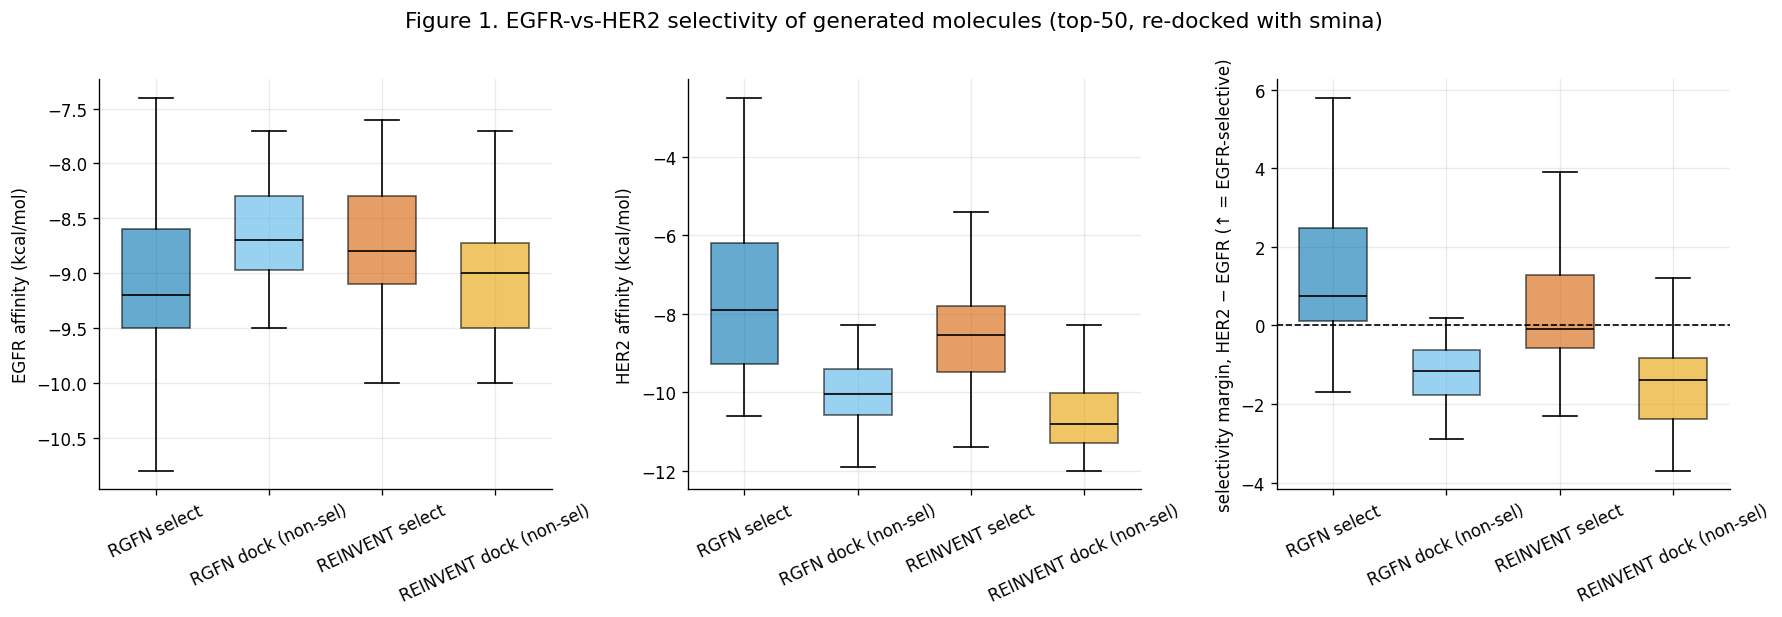

In [4]:
def load_dock(key,tgt):
    d=pd.read_csv(f"{REPO}/dock_seed/sdk_{key}_{tgt}_out.csv").dropna(subset=["affinity"])
    return d.rename(columns={"affinity":tgt})[["smiles",tgt]]

res={}
for name,key in KEY.items():
    m=load_dock(key,"egfr").merge(load_dock(key,"her2"),on="smiles")
    m["margin"]=m["her2"]-m["egfr"]                 # >0 = sélectif pour EGFR
    res[name]=m
    print(f"{name:24s}: EGFR {m.egfr.median():6.2f} | HER2 {m.her2.median():6.2f} | "
          f"marge {m.margin.median():+.2f}  (n={len(m)})")

order=list(KEY)
fig,axs=plt.subplots(1,3,figsize=(15,5))
for ax,(col,lab) in zip(axs,[("egfr","EGFR affinity (kcal/mol)"),
                             ("her2","HER2 affinity (kcal/mol)"),
                             ("margin","selectivity margin, HER2 − EGFR (↑ = EGFR-selective)")]):
    bp=ax.boxplot([res[n][col] for n in order],tick_labels=order,patch_artist=True,
                  widths=.6,showfliers=False)
    for patch,n in zip(bp["boxes"],order): patch.set_facecolor(COLORS[n]); patch.set_alpha(.6)
    for med in bp["medians"]: med.set_color("black")
    ax.set_ylabel(lab); ax.tick_params(axis="x",rotation=25)
axs[2].axhline(0,ls="--",c="k",lw=1)
fig.suptitle("Figure 1. EGFR-vs-HER2 selectivity of generated molecules (top-50, re-docked with smina)",y=1.02,fontsize=13)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/nb16_fig1_selectivity.png"); plt.show()

                             n  scaf_ratio     MW  cLogP    QED    SA
pop                                                                  
RGFN select              11806       0.951  522.5   3.01  0.381  3.69
RGFN dock (non-sel)      16553       0.963  513.7   3.07  0.374  3.61
REINVENT select           6225       0.908  322.5   3.28  0.801  2.78
REINVENT dock (non-sel)   6332       0.852  335.7   3.53  0.774  2.25


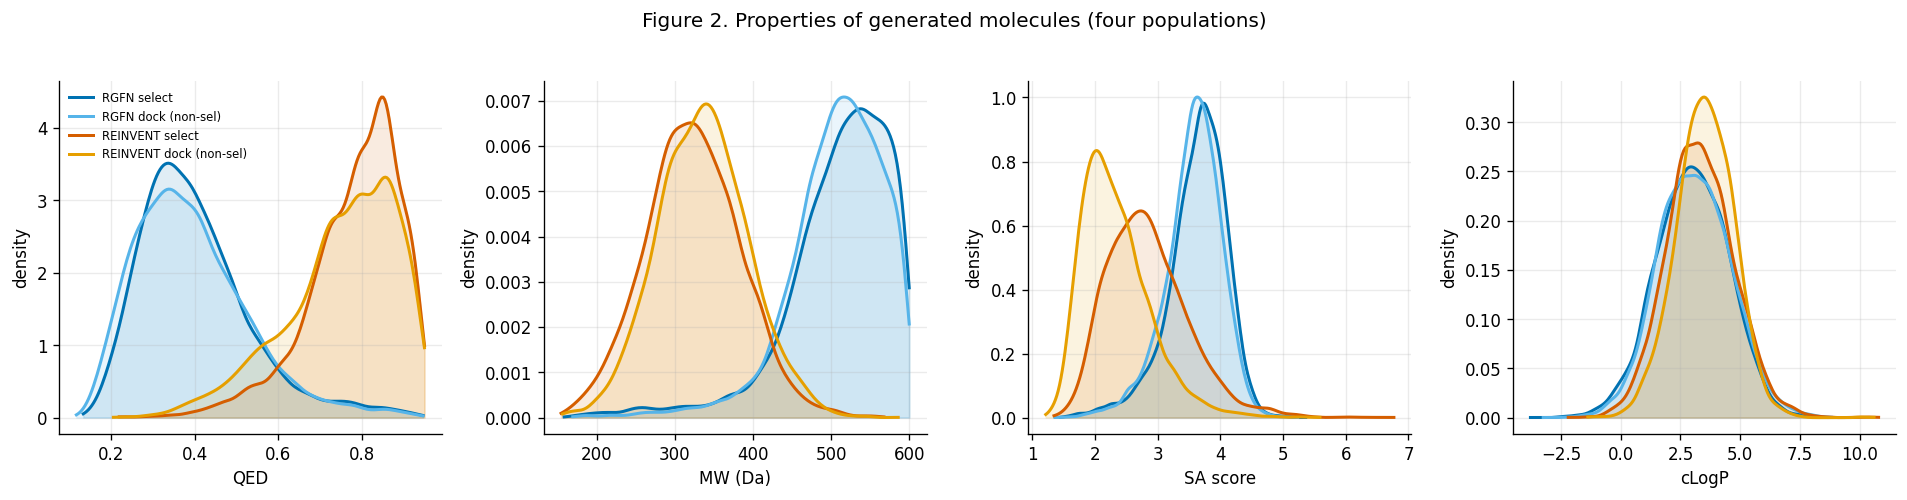

In [5]:
from rdkit.Chem.Scaffolds import MurckoScaffold
def enrich(df):
    df=df.copy()
    df["QED"]=df["mol"].apply(QED.qed); df["SA"]=df["mol"].apply(sascorer.calculateScore)
    df["MW"]=df["mol"].apply(Descriptors.MolWt); df["cLogP"]=df["mol"].apply(Descriptors.MolLogP)
    return df
def nscaf(df): return len({MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in df["mol"]})
POPS={k:(enrich(v) if v is not None and len(v) else v) for k,v in POPS.items()}

print(pd.DataFrame([dict(pop=n,n=len(df),scaf_ratio=round(nscaf(df)/len(df),3),
      MW=round(df.MW.median(),1),cLogP=round(df.cLogP.median(),2),
      QED=round(df.QED.median(),3),SA=round(df.SA.median(),2))
      for n,df in POPS.items() if df is not None and len(df)]).set_index("pop").to_string())

from scipy.stats import gaussian_kde
def kde(ax,col,lab):
    for n,df in POPS.items():
        if df is None or len(df)<5: continue
        x=df[col].values; k=gaussian_kde(x); xs=np.linspace(x.min(),x.max(),200)
        ax.plot(xs,k(xs),color=COLORS[n],lw=1.8,label=n); ax.fill_between(xs,k(xs),color=COLORS[n],alpha=.12)
    ax.set_xlabel(lab); ax.set_ylabel("density")
fig,axes=plt.subplots(1,4,figsize=(16,4))
for ax,(c,l) in zip(axes,[("QED","QED"),("MW","MW (Da)"),("SA","SA score"),("cLogP","cLogP")]): kde(ax,c,l)
axes[0].legend(fontsize=7)
fig.suptitle("Figure 2. Properties of generated molecules (four populations)",y=1.03)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/nb16_fig2_properties.png"); plt.show()

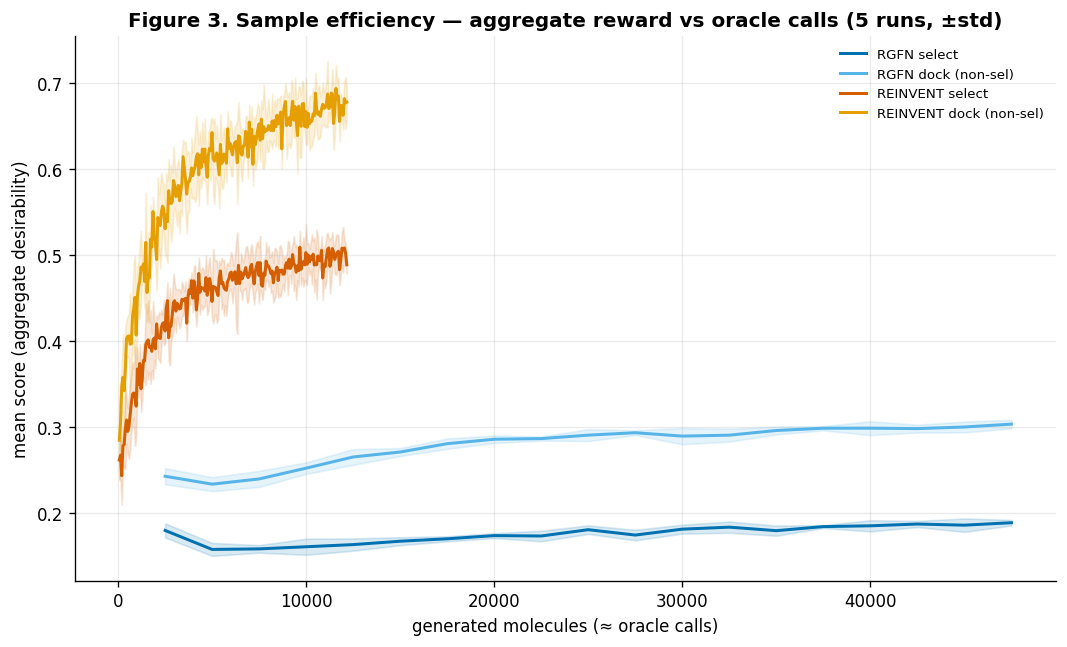

In [6]:
import ast
def rgfn_curve(run_name, last=5, binsize=2500):
    dirs=[d for d in sorted(glob.glob(f"{RGFN}/experiments/{run_name}/*"))
          if glob.glob(f"{d}/all_molecules/molecules_2500.txt")][-last:]
    curves=[]
    for d in dirs:
        sc=[]
        with open(f"{d}/all_molecules/molecules_2500.txt") as fh:
            for line in fh:
                sc.append(ast.literal_eval(line.rstrip().rsplit(", ",1)[-1])["score"])
        sc=np.array(sc); nb=len(sc)//binsize
        x=(np.arange(nb)+1)*binsize
        curves.append(pd.Series([sc[i*binsize:(i+1)*binsize].mean() for i in range(nb)], index=x))
    M=pd.concat(curves,axis=1)
    return M.index.values, M.mean(axis=1).values, M.std(axis=1).values

def rein_curve(pattern, bs=64):
    frames=[pd.read_csv(f).groupby("step")["Score"].mean() for f in glob.glob(pattern)]
    M=pd.concat(frames,axis=1)
    return M.index.values*bs, M.mean(axis=1).values, M.std(axis=1).values

curves = {
 "RGFN select":            rgfn_curve("rgfn_scorer_select"),
 "RGFN dock (non-sel)":    rgfn_curve("rgfn_scorer_dock_multi"),
 "REINVENT select":        rein_curve(f"{REINVENT4}/select_runs/sel_select_s*_1.csv"),
 "REINVENT dock (non-sel)":rein_curve(f"{REINVENT4}/select_runs/sel_dock_multi_s*_1.csv"),
}
fig,ax=plt.subplots(figsize=(9,5.5))
for n,(x,m,s) in curves.items():
    ax.plot(x,m,color=COLORS[n],lw=1.8,label=n); ax.fill_between(x,m-s,m+s,color=COLORS[n],alpha=.15)
ax.set_xlabel("generated molecules (≈ oracle calls)")
ax.set_ylabel("mean score (aggregate desirability)")
ax.set_title("Figure 3. Sample efficiency — aggregate reward vs oracle calls (5 runs, ±std)")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/nb16_fig3_sample_efficiency.png"); plt.show()

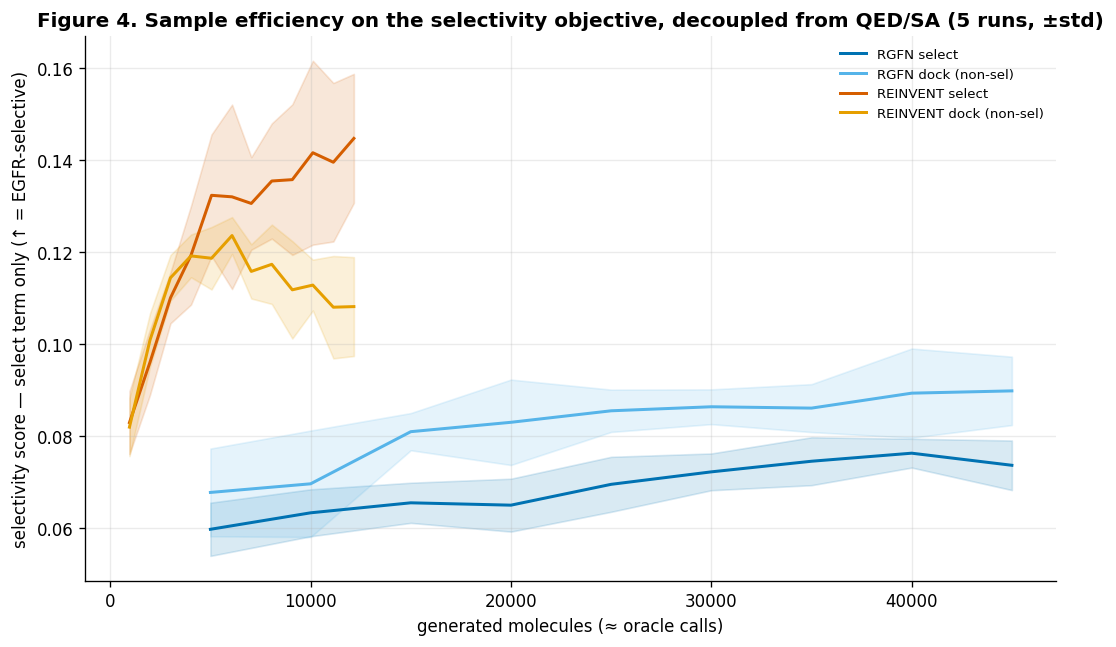

In [7]:
import ast
os.environ["DOCK_2D"]="1"; sys.path.append(REPO)
import scoring.scorer as sc
def select_score(smiles):
    return sc.score(list(smiles), terms=('select',), invalid_value=0.0)

def rgfn_select_curve(run_name, last=5, binsize=5000, sample=200, seed=0):
    rng=np.random.default_rng(seed)
    dirs=[d for d in sorted(glob.glob(f"{RGFN}/experiments/{run_name}/*"))
          if glob.glob(f"{d}/all_molecules/molecules_2500.txt")][-last:]
    curves=[]
    for d in dirs:
        smis=[]
        with open(f"{d}/all_molecules/molecules_2500.txt") as fh:
            for line in fh: smis.append(line.rstrip().rsplit(", ",1)[0])
        smis=np.array(smis,dtype=object); nb=len(smis)//binsize; xs=[]; ys=[]
        for i in range(nb):
            blk=smis[i*binsize:(i+1)*binsize]
            idx=rng.choice(len(blk),size=min(sample,len(blk)),replace=False)
            ys.append(np.nanmean(select_score(blk[idx]))); xs.append((i+1)*binsize)
        curves.append(pd.Series(ys,index=xs))
    M=pd.concat(curves,axis=1); return M.index.values, M.mean(1).values, M.std(1).values

def rein_select_curve(pattern, bs=64, nbin=12, sample=200, seed=0):
    rng=np.random.default_rng(seed); curves=[]
    for f in glob.glob(pattern):
        d=pd.read_csv(f)[["step","SMILES"]]; edges=np.linspace(0,d.step.max(),nbin+1).astype(int)
        xs=[]; ys=[]
        for a,b in zip(edges[:-1],edges[1:]):
            blk=d[(d.step>a)&(d.step<=b)]["SMILES"].values
            if len(blk)==0: continue
            idx=rng.choice(len(blk),size=min(sample,len(blk)),replace=False)
            ys.append(np.nanmean(select_score(blk[idx]))); xs.append(int(b)*bs)
        curves.append(pd.Series(ys,index=xs))
    M=pd.concat(curves,axis=1); return M.index.values, M.mean(1).values, M.std(1).values

curves_sel = {
 "RGFN select":            rgfn_select_curve("rgfn_scorer_select"),
 "RGFN dock (non-sel)":    rgfn_select_curve("rgfn_scorer_dock_multi"),
 "REINVENT select":        rein_select_curve(f"{REINVENT4}/select_runs/sel_select_s*_1.csv"),
 "REINVENT dock (non-sel)":rein_select_curve(f"{REINVENT4}/select_runs/sel_dock_multi_s*_1.csv"),
}
fig,ax=plt.subplots(figsize=(9,5.5))
for n,(x,m,s) in curves_sel.items():
    ax.plot(x,m,color=COLORS[n],lw=1.8,label=n); ax.fill_between(x,m-s,m+s,color=COLORS[n],alpha=.15)
ax.set_xlabel("generated molecules (≈ oracle calls)")
ax.set_ylabel("selectivity score — select term only (↑ = EGFR-selective)")
ax.set_title("Figure 4. Sample efficiency on the selectivity objective, decoupled from QED/SA (5 runs, ±std)")
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(f"{FIGDIR}/nb16_fig4_efficiency_selectonly.png"); plt.show()

In [8]:
def components(smiles):
    me,se=sc._get_surrogate()(list(smiles)); mh,sh=sc._get_her2_surrogate()(list(smiles))
    me=np.nan_to_num(me,0.); se=np.nan_to_num(se,1.); mh=np.nan_to_num(mh,0.); sh=np.nan_to_num(sh,1.)
    egfr=sc._dock_desir(me - sc.LAM_DOCK*se)
    her2pen=1 - sc._dock_desir(mh + sc.LAM_HER2*sh)
    return np.array(egfr), np.array(her2pen)

for name in ["RGFN select","RGFN dock (non-sel)"]:
    df=POPS[name].drop_duplicates("SMILES").head(2000)
    e,h=components(df["SMILES"])
    print(f"{name:20s}: EGFR_desir median={np.median(e):.3f} | (1-HER2 penalty) median={np.median(h):.3f} | product={np.median(e*h):.3f}")

RGFN select         : EGFR_desir median=0.419 | (1-HER2 penalty) median=0.195 | product=0.078
RGFN dock (non-sel) : EGFR_desir median=0.495 | (1-HER2 penalty) median=0.127 | product=0.061


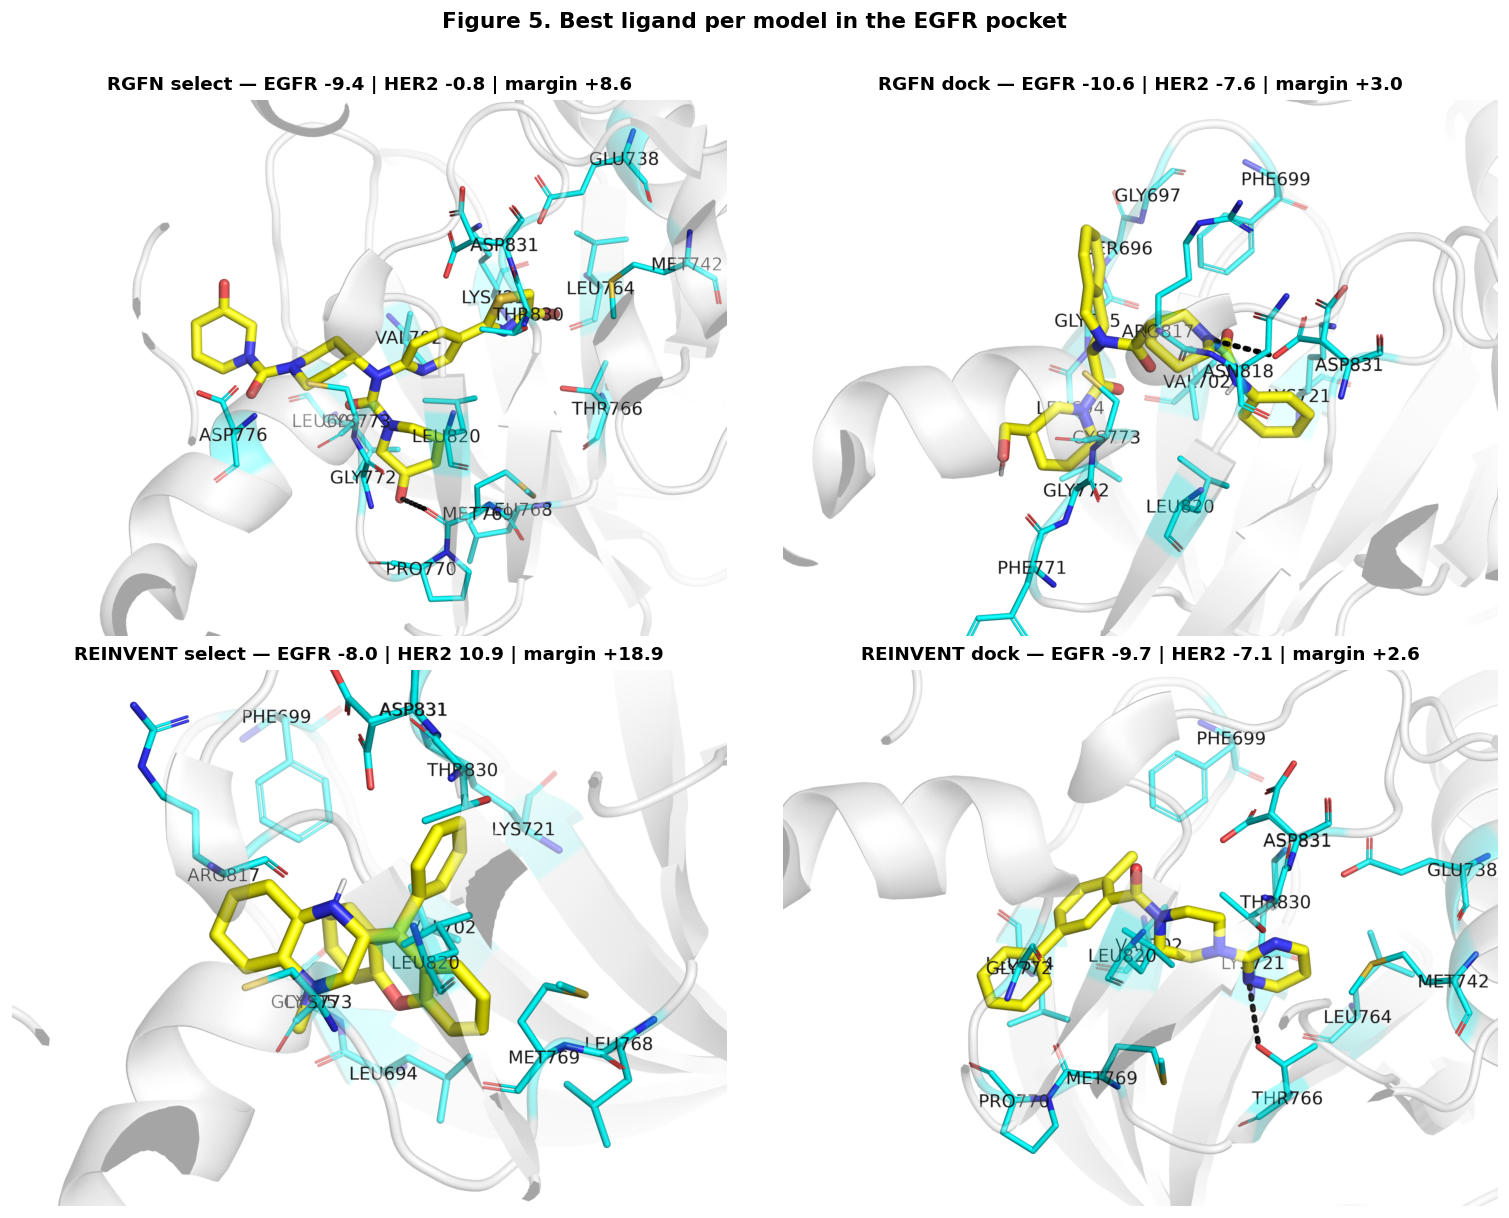

In [11]:
import pandas as pd, os, matplotlib.pyplot as plt, matplotlib.image as mpimg
DS=f"{REPO}/dock_seed"; FIGDIR=f"{REPO}/protein_figures"
best=pd.read_csv(f"{DS}/nb17_best_ligands.csv")
fig,axes=plt.subplots(2,2,figsize=(13,10))
for ax,(i,r) in zip(axes.ravel(), best.iterrows()):
    p=f"{FIGDIR}/interaction_{i}.png"
    ax.imshow(mpimg.imread(p)) if os.path.exists(p) else ax.text(.5,.5,f"interaction_{i} manquant",ha="center")
    ax.axis("off")
    ax.set_title(f"{r['arm']} — EGFR {r['egfr']} | HER2 {r['her2']} | margin {r['margin']:+.1f}",
                 fontsize=11, fontweight="bold")
fig.suptitle("Figure 5. Best ligand per model in the EGFR pocket", y=1.01, fontsize=13, fontweight="bold")
fig.tight_layout(); fig.savefig(f"{FIGDIR}/nb16_fig5_interactions.png", dpi=200, bbox_inches="tight"); plt.show()

## Discussion

Because both generators optimise the same surrogate, this comparison is controlled for information access, unlike the docking comparison of notebook 15. Under that fair setting, RGFN reaches genuine EGFR-over-HER2 selectivity and REINVENT reaches roughly neutral. The broader lesson is a measurement one: a generator must be judged on its output and on an independent oracle, not on the aggregate training reward, which here is confounded by drug-likeness and by the difficulty of the objective.

Several limitations bound these results. The HER2 surrogate is weaker than the EGFR one (R² ≈ 0.70), so the anti-target signal is noisier. A positive HER2 docking score is a failed placement, i.e. a non-binder, not a favourable energy, so single-molecule margins built on such scores are inflated and only the population medians should be trusted. Five seeds give low statistical power, and no molecule was validated experimentally.

## Conclusion

An explicit anti-target term yields molecules that are EGFR-selective under an independent 3D oracle, and RGFN reaches that selectivity better than REINVENT when both optimise the same surrogate. The result holds on the output and the oracle, not on the aggregate reward, which conflates selectivity with drug-likeness. A stronger HER2 model and experimental validation are the natural next steps.